# GTOK

### Introduction

The goal of this notebook is to validate the data we can get from a setelite with data from an on-the-field sensor. 

The expectation is that the sensor will have more accurate data, out goal will then be to see what offset we can use for a better approximation.

With more sensor data from different regions we can make what we call the "satelite error" factor smaller

### Validation One - air & soil data (temperature, humidity, etc)

#### Step 1.1 - convert HA export to timeseries data

We have a CSV with export from an in-the-field sensor that is connected to Home Assistant, we first have to pre-process the data to create a timesearies of all the different sensors.

| entity_id | state | last_changed |
|-------------|-------|----------|
| humidity_1  | xx | xx-xx-xxxx xx:xx:xx|

Our goal will be to get from the above format to a format similar to this

| last_changed | air_humidity | air_temperature | rainfall_total | soil_humidity | soil_temperature |
|-------------|-------|----------|----|----|----|
| xx-xx-xxxx xx:xx:xx  | xx | xx | xx | xx | xx |

In [ ]:
# Step 1.1 convert HA export to time series

import pandas as pd
import numpy as np

INPUT_HOME_ASSISTANT_EXPORT_CSV = "../data/HA_export_weather_data_august_2025.csv"
OUTPUT_TIME_SERIES_CSV = "../data/HA_export_converted_timeseries_data_august_2025.csv"

# Read the CSV
df = pd.read_csv(INPUT_HOME_ASSISTANT_EXPORT_CSV)

# ensure datetime
df['last_changed'] = pd.to_datetime(df['last_changed'])

# Sort by time
df = df.sort_values('last_changed')

# Pivot the table
# Index is datetime ('last_changed'), columns are sensors, values are states
# This will create a sparse dataframe first (lots of NaNs)
df_pivot = df.pivot_table(index='last_changed', columns='entity_id', values='state', aggfunc='first')

# Forward fill. This fills "no report" gaps with the previous signal.
df_filled = df_pivot.ffill()

# NOW replace 'unavailable' with NaN.
# This ensures that if the state actually BECAME 'unavailable', it stays NaN until a new valid number comes in.
df_filled = df_filled.replace('unavailable', 'nan')

print("#####################################################")
print("Timeseries - replace 'unavailable' with 'NaN")
print(df_filled.head())

# Coerce to numeric
for col in df_filled.columns:
    df_filled[col] = pd.to_numeric(df_filled[col], errors='ignore')

# Save
df_filled.to_csv(OUTPUT_TIME_SERIES_CSV)
print(f"Successfully converted data. Saved to {OUTPUT_TIME_SERIES_CSV}")
print("Head of new DataFrame:")
print(df_filled.head())


In [ ]:
# Step 1.1 (only load sensor data)
import pandas as pd

OUTPUT_TIME_SERIES_CSV = "../data/HA_export_converted_timeseries_data_august_2025.csv"
OUTPUT_TIME_SERIES_HOURLY_CSV = "../data/HA_export_converted_timeseries_data_hourly_august_2025.csv"

sensor_data_df = pd.read_csv(OUTPUT_TIME_SERIES_CSV)
sensor_data_df['valid_time'] = pd.to_datetime(sensor_data_df['last_changed'], format='mixed')
sensor_data_df = sensor_data_df.set_index("valid_time")

print("### Original Sensor Data ###")
print(sensor_data_df.head())

sensor_data_hourly_df = sensor_data_df.resample('h').agg({
    'air_temperature': 'mean',
    'air_humidity': 'mean',
    'soil_temperature': 'mean',
    'soil_humidity': 'mean',
    'rainfall_total': 'sum'
})

sensor_data_hourly_df.to_csv(OUTPUT_TIME_SERIES_HOURLY_CSV)
print("### Resampled Hourly Sensor Data ###")
print(sensor_data_hourly_df.head())



### Original Sensor Data ###
                                                      last_changed  \
valid_time                                                           
2025-08-10 11:00:00+00:00         2025-08-10 11:00:00.000000+00:00   
2025-08-10 11:02:30.042000+00:00  2025-08-10 11:02:30.042000+00:00   
2025-08-10 11:02:30.046000+00:00  2025-08-10 11:02:30.046000+00:00   
2025-08-10 11:11:12.729000+00:00  2025-08-10 11:11:12.729000+00:00   
2025-08-10 11:11:12.731000+00:00  2025-08-10 11:11:12.731000+00:00   

                                  air_humidity  air_temperature  \
valid_time                                                        
2025-08-10 11:00:00+00:00                 47.4             28.4   
2025-08-10 11:02:30.042000+00:00          47.4             28.4   
2025-08-10 11:02:30.046000+00:00          45.6             28.4   
2025-08-10 11:11:12.729000+00:00          45.6             28.4   
2025-08-10 11:11:12.731000+00:00          43.6             28.7   

          

#### Step 1.2 - download satelite data for same location

The CSV we have so far has the following attributes:
* it is between the **10.08.2025** and **31.08.2025**
* it humidity and temperature for the air, humidity and temperature for the soil and also a calculation of total rainfall, and we have the following assumptions
    - temperature is presented in $\degree C$
    - humidity is presented in percentages
    - unclear what total rainfall represents or is presented as
* additional questions mention the location being approximately **lat: 46.84758540334098** and **lon: 23.60230871791939**

Our next move is to download the CDS data for this specific location in this specific timerange, and then compare the values

In [23]:
# Step 1.2.1 download CDS data

# Link to dataset: https://cds.climate.copernicus.eu/datasets/reanalysis-era5-land-timeseries?tab=overview

import cdsapi

INPUT_LATITUDE = 46.84758540334098
INPUT_LONGITUDE = 23.60230871791939

zip_file_path = "../download/CDS_download_august_2025.zip"
unzipped_folder_path = "../download/CDS_download_august_2025/"

dataset = "reanalysis-era5-land-timeseries"
request = {
    "variable": [
        "2m_dewpoint_temperature",
        "2m_temperature",
        "surface_pressure",
        "total_precipitation",
        "surface_solar_radiation_downwards",
        "surface_thermal_radiation_downwards",
        "skin_temperature",
        "snow_cover",
        "soil_temperature_level_1",
        "soil_temperature_level_2",
        "soil_temperature_level_3",
        "soil_temperature_level_4",
        "volumetric_soil_water_level_1",
        "volumetric_soil_water_level_2",
        "volumetric_soil_water_level_3",
        "volumetric_soil_water_level_4",
        "10m_u_component_of_wind",
        "10m_v_component_of_wind"
        ],
    "location": {
        "longitude": INPUT_LATITUDE, 
        "latitude": INPUT_LONGITUDE},
    "date": ["2025-08-10/2025-08-31"],
    "data_format": "CSV",
    "download_format": "archived"
}

client = cdsapi.Client()
client.retrieve(dataset, request, zip_file_path)

2026-01-12 23:31:34,947 WARNING [2025-06-04T00:00:00] This dataset provides user-selected location timeseries of [ERA5 Land data](https://doi.org/10.24381/cds.e2161bac) for a limited set of variables. Its content may be undergo changes over time (e.g. file format, data file structure, deprecation etc) and is **not recommended for use in a production environment**. 

For users interested in large regions, the original ERA5 Land catalogue entry remains the more efficient option. 
We will make every effort to notify users of changes, either through this banner and/or the [Forum](https://forum.ecmwf.int/).
2026-01-12 23:31:34,950 INFO Request ID is d30096c9-2a45-4e9b-b6a2-d70406d41967
2026-01-12 23:31:35,088 INFO status has been updated to accepted
2026-01-12 23:31:49,017 WARNING Download format not supported for this dataset. Defaulting to zip.
2026-01-12 23:31:49,018 INFO status has been updated to running
2026-01-12 23:31:56,774 INFO status has been updated to successful


26be07f7e8e112eaa6df7fec11f2cdbc.zip:   0%|          | 0.00/43.3k [00:00<?, ?B/s]

'../download/CDS_download_august_2025.zip'

**CDS Data Explained**

| Param. name in request              | Param. name in file | Data Group     |
|-------------------------------------|---------------------|----------------|
| 2m_dewpoint_temperature             | d2m                 | 2m temperature |
| 2m_temperature                      | t2m                 | 2m temperature | 
| surface_pressure                    | sp          | preasure precipitation | 
| total_precipitation                 | tp          | preasure precipitation |
| surface_solar_radiation_downwards   | ssrd                | radiation heat |
| surface_thermal_radiation_downwards | strd                | radiation heat |
| skin_temperature                    | skt               | skin temperature |
| snow_cover                          | snowc                         | snow |
| soil_temperature_level_1            | stl1              | soil temperature |
| soil_temperature_level_2            | stl2              | soil temperature |    
| soil_temperature_level_3            | stl3              | soil temperature |
| soil_temperature_level_4            | stl4              | soil temperature |
| volumetric_soil_water_level_1       | swl1                    | soil water |
| volumetric_soil_water_level_2       | swl2                    | soil water |
| volumetric_soil_water_level_3       | swl3                    | soil water |
| volumetric_soil_water_level_4       | swl4                    | soil water |
| 10m_u_component_of_wind             | u10                           | wind |
| 10m_v_component_of_wind             | v10                           | wind |    

## Calculating Relative Humidity

### Description

Relative Humidity Calculation (Simplified)

The Concept Think of the air as a sponge or a tank. Relative Humidity is simply a percentage that tells us: "How full is the tank?"

**The Tank Size (Saturation)**: The hotter the air, the bigger its capacity to hold water. We calculate this theoretical maximum using the current Air Temperature.

**The Water Level (Actual)**: The Dewpoint Temperature represents the point where the air would be 100% full. Therefore, using the dewpoint allows us to calculate the specific amount of water currently present.

### Formula (August-Roche-Magnus) 

The Formula We use the August-Roche-Magnus approximation, a standard meteorological formula.

$$ RH = 100 \times \frac{\exp(\text{Dewpoint Factor})}{\exp(\text{Temperature Factor})} $$

Why it works without Pressure: In standard physics formulas, you normally need Atmospheric Pressure to find the absolute mass of the water. However, because we are calculating a ratio (Percentage), the pressure variable appears in both the top and bottom of the fraction and cancels itself out. This makes the calculation faster and requires fewer inputs while remaining highly accurate.

### Constants

**17.67** and **243.5**

These are empirical curve-fitting constants derived specifically for the Magnus formula (this specific set comes from Bolton, 1980).

Water doesn't evaporate in a straight line; as it gets hotter, it evaporates exponentially faster. These two numbers define the specific "shape" of that exponential curve for water.
Note: If you were calculating this over ice instead of water, these numbers would change (typically to ~21.87 and ~265.5) because ice sublimates differently than water evaporates.

In [18]:
# Calculate Relative Humidity via the simpler August-Roche-Magnus approximation.

import numpy as np

def calculate_rh_simple_for_row(row):
    temp_c = row['air_temp_C']
    td_c = row['dewpoint_temp_C']
        
    # Constants (derived from Bolton 1980)
    a = 17.67 
    b = 243.5
    
    # 1. Calculate the exponential part for both Temp and Dewpoint
    sat_vapor_factor = np.exp((a * temp_c) / (b + temp_c))
    actual_vapor_factor = np.exp((a * td_c) / (b + td_c))
    
    # 2. Simple Ratio
    rh = 100.0 * (actual_vapor_factor / sat_vapor_factor)
    
    return np.clip(rh, 0, 100)

In [19]:
# Step 1.2.2 load CDS data into dataframes by group

import os
import zipfile
import glob

import pandas as pd

zip_file_path = "../download/CDS_download_august_2025.zip"
unzipped_folder_path = "../download/CDS_download_august_2025/"

# Unzip the CDS file if it is not already downloaded
if not (os.path.exists(unzipped_folder_path) and os.path.isdir(unzipped_folder_path) and os.listdir(unzipped_folder_path)):
    print("ZIP files is not yet unzipped. Extrating files ...")
    with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
        zip_ref.extractall(unzipped_folder_path)

# List all CSV files in the folder
files = glob.glob(unzipped_folder_path + "*.csv")
air_temperature_csv = [f for f in files if '2m-temperature' in f][0]
preasure_csv = [f for f in files if 'pressure' in f][0]

cds_airtemp_df = pd.read_csv([f for f in files if '2m-temperature' in f][0])
cds_airtemp_df['valid_time'] = pd.to_datetime(cds_airtemp_df['valid_time'], format='mixed')
cds_airtemp_df = cds_airtemp_df.set_index("valid_time")
cds_airtemp_df.index = cds_airtemp_df.index.tz_localize('UTC')
# print("### CDS Air Temperature ###")
# print(cds_airtemp_df)
# print(cds_airtemp_df.head())

cds_soiltemp_df = pd.read_csv([f for f in files if 'soil-temperature' in f][0])
cds_soiltemp_df['valid_time'] = pd.to_datetime(cds_soiltemp_df['valid_time'], format='mixed')
cds_soiltemp_df = cds_soiltemp_df.set_index("valid_time")
cds_soiltemp_df.index = cds_soiltemp_df.index.tz_localize('UTC')
# print("### CDS Soil Temperature ###")
# print(cds_soiltemp_df)
# print(cds_soiltemp_df.head())

cds_soilwater_df = pd.read_csv([f for f in files if 'soil-water' in f][0])
cds_soilwater_df['valid_time'] = pd.to_datetime(cds_soilwater_df['valid_time'], format='mixed')
cds_soilwater_df = cds_soilwater_df.set_index("valid_time")
cds_soilwater_df.index = cds_soilwater_df.index.tz_localize('UTC')
# print("### CDS Soil Water ###")
# print(cds_soilwater_df)
# print(cds_soilwater_df.head())

cds_merged = pd.concat([cds_airtemp_df, cds_soiltemp_df, cds_soilwater_df], axis=1)
# print("### CDS Merged Dataset ###")
# print(cds_merged)
# print(cds_merged.head())

cds_merged = cds_merged.loc[:, ~cds_merged.columns.duplicated()]

# Get / Calculate values for air
cds_merged['air_temp_C'] = cds_merged['t2m'] - 273.15 # converting K to C
cds_merged['dewpoint_temp_C'] = cds_airtemp_df["d2m"] - 273.15 # converting K to C
cds_merged['air_huminidty'] = cds_merged.apply(calculate_rh_simple_for_row, axis=1)

# Get / Calculate values for soil
cds_merged['soil_temp_C'] = cds_merged['stl1'] - 273.15 # converting K to C

# Weighted by depth: (7cm * L1 + 21cm * L2) / 28cm Total
cds_merged['soil_moisture_weighted'] = (
    (cds_merged['swvl1'].clip(lower=0.0) * 7 + 
    cds_merged['swvl2'].clip(lower=0.0) * 21) 
    / 28) * 100

# print("### CDS Merged Dataset (after conversion) ###")
# print(cds_merged)
# print(cds_merged.head())




# Merge on timestamp (Inner join to find matching hours)
df_merged = sensor_data_hourly_df.join(cds_merged, lsuffix='_sensor', rsuffix='_sat', how='inner')

print("### CDS Merged Dataset (after conversion) ###")
print(df_merged)
print(df_merged.head())


### CDS Merged Dataset (after conversion) ###
                           air_temperature  air_humidity  soil_temperature  \
valid_time                                                                   
2025-08-10 11:00:00+00:00        28.915789     44.057895         21.168421   
2025-08-10 12:00:00+00:00        29.562500     41.350000         21.875000   
2025-08-10 13:00:00+00:00        29.672222     40.650000         22.255556   
2025-08-10 14:00:00+00:00        29.606667     41.746667         22.646667   
2025-08-10 15:00:00+00:00        29.287500     44.937500         22.900000   
...                                    ...           ...               ...   
2025-08-31 09:00:00+00:00        16.273684     87.926316         17.915789   
2025-08-31 10:00:00+00:00        16.084211     90.742105         17.952632   
2025-08-31 11:00:00+00:00        15.306667     94.106667         17.920000   
2025-08-31 12:00:00+00:00        14.840000     96.880000         17.925000   
2025-08-31 13:00:0


COMPARISON REPORT (Matches: 507 hours)
Air Temp Bias: -17.51°C
Humidity Bias: 48.15%


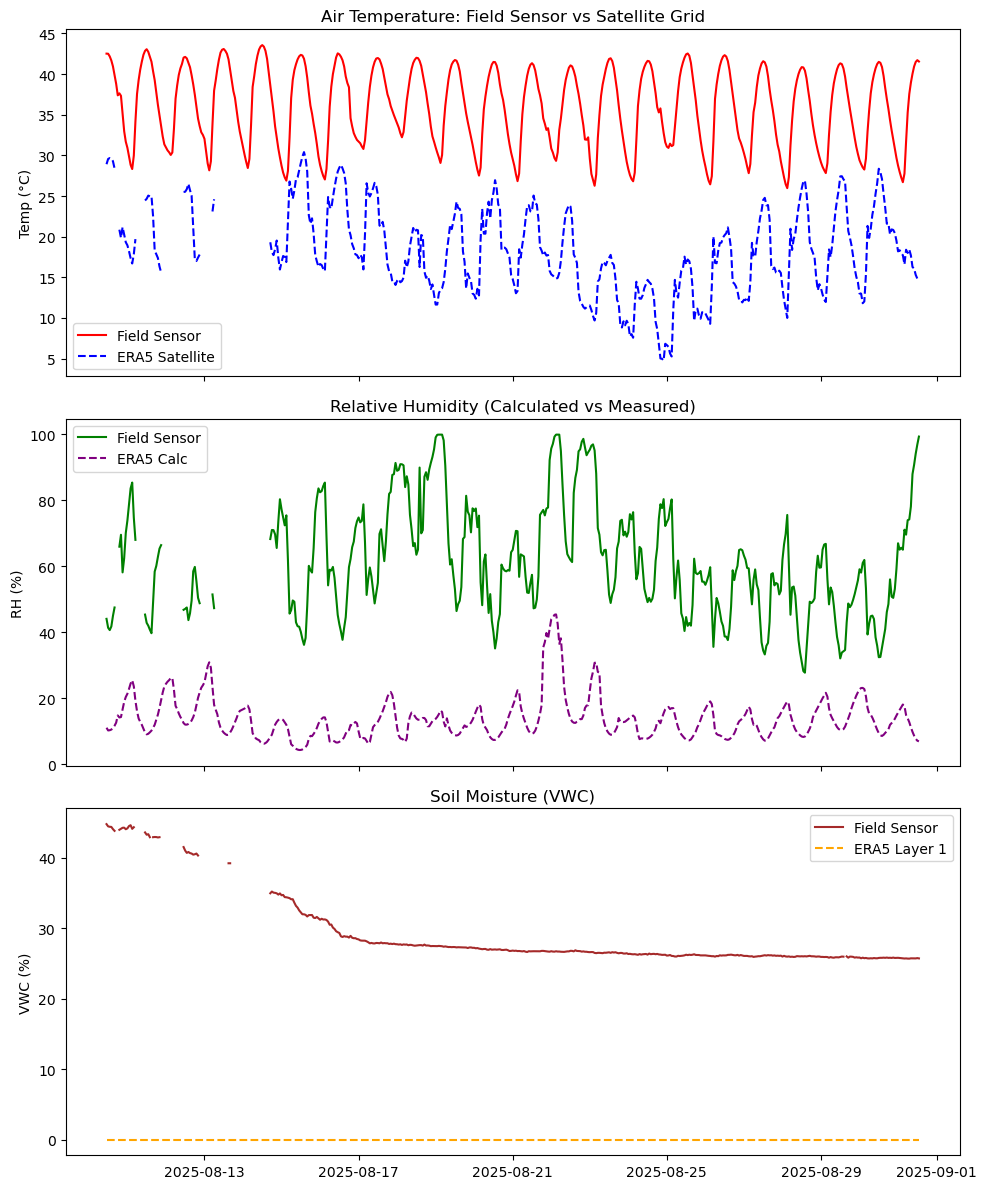

In [22]:
# Analyzing the data

import matplotlib.pyplot as plt

# Calculate Bias (Sensor - Satellite)
df_merged['temp_bias'] = df_merged['air_temperature'] - df_merged['air_temp_C']
df_merged['rh_bias'] = df_merged['air_humidity'] - df_merged['air_huminidty']

# Report Stats
print(f"\nCOMPARISON REPORT (Matches: {len(df_merged)} hours)")
print(f"Air Temp Bias: {df_merged['temp_bias'].mean():.2f}°C")
print(f"Humidity Bias: {df_merged['rh_bias'].mean():.2f}%")

# --- VISUALIZATION ---
fig, axes = plt.subplots(3, 1, figsize=(10, 12), sharex=True)

# Plot 1: Air Temp
axes[0].set_title("Air Temperature: Field Sensor vs Satellite Grid")
axes[0].plot(df_merged.index, df_merged['air_temp_C'], label='Field Sensor', color='red')
axes[0].plot(df_merged.index, df_merged['air_temperature'], label='ERA5 Satellite', color='blue', linestyle='--')
axes[0].legend()
axes[0].set_ylabel("Temp (°C)")

# Plot 2: Relative Humidity (The Calculated One)
axes[1].set_title("Relative Humidity (Calculated vs Measured)")
axes[1].plot(df_merged.index, df_merged['air_humidity'], label='Field Sensor', color='green')
axes[1].plot(df_merged.index, df_merged['air_huminidty'], label='ERA5 Calc', color='purple', linestyle='--')
axes[1].legend()
axes[1].set_ylabel("RH (%)")

# Plot 3: Soil Moisture
axes[2].set_title("Soil Moisture (VWC)")
axes[2].plot(df_merged.index, df_merged['soil_humidity'], label='Field Sensor', color='brown')
axes[2].plot(df_merged.index, df_merged['soil_moisture_weighted'], label='ERA5 Layer 1', color='orange', linestyle='--')
axes[2].legend()
axes[2].set_ylabel("VWC (%)")

plt.tight_layout()

In [25]:
# Show map

import folium

INPUT_LATITUDE = 46.84758540334098
INPUT_LONGITUDE = 23.60230871791939

# Your coordinates (Lat, Lon)
location = [INPUT_LATITUDE, INPUT_LONGITUDE]  # NOTE: Folium uses [Lat, Lon]

# 1. Create the base map
m = folium.Map(location=location, zoom_start=15)

# 2. Add 'Satellite' tiles (Esri World Imagery is free and high quality)
folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Esri',
    name='Esri Satellite',
    overlay=False,
    control=True
).add_to(m)

# 3. Add a marker for your exact spot
folium.Marker(
    location=location,
    popup="My Location",
    icon=folium.Icon(color="red", icon="info-sign"),
).add_to(m)

# 4. Display map
m

In [4]:
import folium
import numpy as np

# --- 1. Settings ---
INPUT_LATITUDE = 46.84758540334098
INPUT_LONGITUDE = 23.60230871791939

center_lat, center_lon = INPUT_LATITUDE, INPUT_LONGITUDE
square_size_km = 9.0  # Total width
half_side = square_size_km / 2.0

# --- 2. Calculate Corner Coordinates ---
# 1 degree latitude is approx 111.32 km everywhere
lat_change = half_side / 111.32

# 1 degree longitude depends on the latitude: 111.32 * cos(lat)
# We use cosine of the latitude (converted to radians) to adjust
lon_change = half_side / (111.32 * np.cos(np.radians(center_lat)))

# Define the 4 corners bounding box: [ [South-West], [North-East] ]
# Bounds format for Folium: [[LatMin, LonMin], [LatMax, LonMax]]
bounds = [
    [center_lat - lat_change, center_lon - lon_change], # Bottom-Left
    [center_lat + lat_change, center_lon + lon_change]  # Top-Right
]

# --- 3. Draw Map ---
m = folium.Map(location=[center_lat, center_lon], zoom_start=12)

# Add Satellite Layer
folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Esri',
    name='Esri Satellite'
).add_to(m)

# Draw the 9km square
folium.Rectangle(
    bounds=bounds,
    color="#ff7800",      # Border color (Orange)
    fill=True,
    fill_color="#ffff00", # Fill color (Yellow)
    fill_opacity=0.2,     # Semi-transparent
    popup="9x9 km Grid Cell"
).add_to(m)

# Add Center Marker
folium.Marker([center_lat, center_lon], popup="Center").add_to(m)

m